# Heart Disease Dataset — Exploratory Data Analysis & Regression (R — Base R)

Complete analysis pipeline for a heart-disease dataset (**10,000 rows × 21 columns**), written in
**base R only** — no external packages required. Covers:

1. **Dataset view** — shape, columns, types, unique value counts
2. **Summary statistics** — numerical summaries, categorical summaries, key metrics
3. **Missing values** — total + per-column counts, rows with NA, imputation (mean / mode)
4. **Duplicate records** — count + dedup summary
5. **Descriptive stats** — target prevalence, age/BMI ranges, correlation with target
6. **Correlation** — top 10 feature–target correlations + numeric correlation heatmap
7. **Histograms** — distributions of all numeric features
8. **Boxplots** — numeric features grouped by heart-disease status
9. **Scatter plots** — Age vs BMI and Cholesterol vs BMI, colored by target
10. **Outliers** — IQR 1.5×IQR rule detection per feature
11. **Frequency tables** — value counts for categorical features
12. **Unique values** — per-column unique-count summary
13. **Linear regression** — single feature → target (2 cells, 1 plot)
14. **Multiple linear regression** — all numeric features → target (2 cells, 1 plot)

> **Requirements:** R 4.0+ with the IRkernel selected for this notebook
> (one-time setup: `install.packages("IRkernel"); IRkernel::installspec()`).
>
> **Data source:** the loader below automatically searches for `heart_disease.csv` next to this
> notebook. Set `DATA_PATH` in the next cell to point at your own CSV, or drop your file in the
> same folder under that name. If no CSV is found, a synthetic sample with the same schema
> (10,000 × 21) is generated so every section stays runnable.

In [26]:
# Setup -- base R only, no packages needed
options(width = 140, scipen = 999, digits = 4)

RANDOM_STATE <- 42

find_col <- function(df, ...) {
  # Case-insensitive column lookup (ignores spaces/underscores). Returns column name or NULL.
  targets <- c(...)
  norm <- function(x) tolower(gsub("[ _]", "", x))
  lookup <- norm(names(df))
  hit <- match(norm(targets), lookup, nomatch = 0)
  hit <- hit[hit > 0]
  if (length(hit) > 0) names(df)[hit[1]] else NULL
}

encode_target <- function(x) {
  # 0/1 encoding of the target; works for Yes/No text or 0/1 numeric columns.
  if (is.numeric(x)) return(as.integer(x))
  s <- tolower(trimws(as.character(x)))
  mapped <- ifelse(s %in% c("yes", "y", "true", "1"), 1L,
                   ifelse(s %in% c("no", "n", "false", "0"), 0L, NA_integer_))
  if (anyNA(mapped)) {
    # fallback: alphabetical factor order minus 1 (No -> 0, Yes -> 1 for Yes/No data)
    return(as.integer(factor(x)) - 1L)
  }
  as.integer(mapped)
}

cat("Setup complete. Using", R.version.string, "- base R only, no extra packages.\n")

Setup complete. Using R version 4.6.1 (2026-06-24 ucrt) - base R only, no extra packages.


In [27]:
# >>> Option A: point directly at your own CSV file <<<
DATA_PATH <- NULL  # e.g. DATA_PATH <- "my_heart_data.csv"

candidate_paths <- c(DATA_PATH, "heart_disease.csv", "heart.csv", "heart_disease_data.csv",
                     "data/heart_disease.csv", "../heart_disease.csv", "../heart.csv")
candidate_paths <- candidate_paths[!is.na(candidate_paths)]
found <- candidate_paths[file.exists(candidate_paths)]

if (length(found) > 0) {
  df <- read.csv(found[1], stringsAsFactors = FALSE, na.strings = c("NA", ""))
  data_source <- found[1]
} else {
  # --------------------------------------------------------------
  # Option B (fallback): synthetic heart-disease-style sample dataset
  # Same schema as the target dataset: 10,000 rows x 21 columns
  # --------------------------------------------------------------
  set.seed(RANDOM_STATE)
  n <- 9960

  age <- pmin(pmax(rnorm(n, 55, 13.5), 25), 85)
  bmi <- pmin(pmax(rnorm(n, 28.6, 6), 15), 60)
  chol <- pmin(pmax(185 + 0.9 * (age - 55) + 1.4 * (bmi - 28) + rnorm(n, 0, 32), 120), 450)
  trig <- pmin(pmax(exp(rnorm(n, 4.9, 0.45)) + 1.2 * (bmi - 28), 50), 650)
  sysbp <- pmin(pmax(112 + 0.45 * (age - 55) + 0.55 * (bmi - 28) + rnorm(n, 0, 11), 90), 200)
  diabp <- pmin(pmax(72 + 0.18 * (age - 55) + 0.28 * (bmi - 28) + rnorm(n, 0, 7), 55), 125)
  gluc <- pmin(pmax(92 + 0.8 * (bmi - 28) + rnorm(n, 0, 16), 70), 320)
  phys_health <- pmin(rexp(n, 1 / 4.2), 30)
  mental_health <- pmin(rexp(n, 1 / 4.6), 30)
  sleep <- pmin(pmax(rnorm(n, 7.1, 1.3), 3), 12)

  male <- runif(n) < 0.48
  yes <- function(p) ifelse(runif(n) < p, "Yes", "No")

  smoke <- yes(0.12 + 0.004 * pmax(age - 55, 0))
  alcohol <- yes(0.14)
  diabetes <- yes(0.06 + 0.003 * pmax(bmi - 28, 0) + ifelse(gluc > 140, 0.25, 0))
  stroke <- yes(0.02 + 0.0008 * pmax(age - 55, 0))
  active <- yes(0.78 - 0.004 * pmax(age - 55, 0))
  diffwalk <- yes(0.10 + 0.006 * pmax(age - 55, 0))
  asthma <- yes(0.14)
  kidney <- yes(0.025 + 0.001 * pmax(age - 55, 0))
  skin <- yes(0.06 + 0.0012 * pmax(age - 55, 0))

  logit <- -3.1 + 0.055 * (age - 55) + 0.028 * (bmi - 28) + 0.005 * (chol - 200) +
    0.008 * (sysbp - 125) + 0.45 * (smoke == "Yes") + 0.55 * (diabetes == "Yes") +
    0.50 * (stroke == "Yes") + 0.30 * (active == "No") + 0.20 * male + 0.25 * (kidney == "Yes")
  heart <- yes(plogis(logit))

  df <- data.frame(
    Age = round(age), Sex = ifelse(male, "Male", "Female"), BMI = round(bmi, 1),
    Cholesterol = round(chol), Triglycerides = round(trig),
    SystolicBP = round(sysbp), DiastolicBP = round(diabp), Glucose = round(gluc),
    PhysicalHealth = round(phys_health), MentalHealth = round(mental_health),
    SleepTime = round(sleep, 1), Smoking = smoke, AlcoholDrinking = alcohol,
    Stroke = stroke, DiffWalking = diffwalk, Diabetes = diabetes,
    PhysicalActivity = active, Asthma = asthma, KidneyDisease = kidney,
    SkinCancer = skin, HeartDisease = heart,
    stringsAsFactors = FALSE
  )

  # sprinkle sparse missing values + a handful of exact duplicates
  na_plan <- list(c("Age", 0.004), c("BMI", 0.003), c("Cholesterol", 0.008),
                  c("SleepTime", 0.002), c("Smoking", 0.0015))
  for (item in na_plan) {
    col <- item[1]
    df[[col]][sample(nrow(df), round(as.numeric(item[2]) * nrow(df)))] <- NA
  }
  df <- rbind(df, df[sample(nrow(df), 40), ])
  df <- df[sample(nrow(df)), ]
  rownames(df) <- NULL
  data_source <- "synthetic fallback (no CSV file found)"
}

# target column auto-detection (edit manually if your target is named differently)
TARGET_COL <- find_col(df, "HeartDisease", "heart_disease", "target", "disease",
                       "heartdiseasepresence", "TenYearCHD")
if (is.null(TARGET_COL)) TARGET_COL <- names(df)[ncol(df)]

cat("Data source   :", data_source, "\n")
cat(sprintf("Loaded shape  : %s rows x %d columns\n", format(nrow(df), big.mark = ","), ncol(df)))
cat("Target column :", TARGET_COL, "| values:", paste(head(unique(df[[TARGET_COL]]), 6), collapse = ", "), "\n")
head(df)

Data source   : heart_disease.csv 
Loaded shape  : 10,000 rows x 21 columns
Target column : HeartDisease | values: No, Yes 


,Age,Sex,BMI,Cholesterol,Triglycerides,SystolicBP,DiastolicBP,Glucose,PhysicalHealth,MentalHealth,⋯,Smoking,AlcoholDrinking,Stroke,DiffWalking,Diabetes,PhysicalActivity,Asthma,KidneyDisease,SkinCancer,HeartDisease
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,69,Female,38.3,233,100,120,60,101,3,9,⋯,Yes,No,No,Yes,No,Yes,No,No,No,No
2,46,Male,22.5,184,160,99,83,84,1,2,⋯,No,No,No,No,No,Yes,No,No,No,No
3,55,Female,32.5,174,315,106,69,110,2,1,⋯,No,Yes,No,No,Yes,Yes,No,No,No,No
4,54,Male,34.6,130,130,110,71,113,10,1,⋯,No,No,No,Yes,No,Yes,No,No,No,No
5,59,Male,25.0,203,237,113,80,70,8,1,⋯,No,No,No,No,No,Yes,No,No,No,No
6,52,Male,28.4,225,165,109,65,116,1,13,⋯,No,No,No,No,No,Yes,No,No,No,No


## 1. Dataset View
Shape, column names, data types, and per-column unique value counts. The overview table gives a
first impression of which features are continuous, which are categorical, and how many distinct
values each column carries.

In [28]:
cat(sprintf("Dataset shape : %s rows x %d columns\n", format(nrow(df), big.mark = ","), ncol(df)))
cat("Column names  :", paste(names(df), collapse = ", "), "\n\n")
head(df, 10)

Dataset shape : 10,000 rows x 21 columns
Column names  : Age, Sex, BMI, Cholesterol, Triglycerides, SystolicBP, DiastolicBP, Glucose, PhysicalHealth, MentalHealth, SleepTime, Smoking, AlcoholDrinking, Stroke, DiffWalking, Diabetes, PhysicalActivity, Asthma, KidneyDisease, SkinCancer, HeartDisease 



,Age,Sex,BMI,Cholesterol,Triglycerides,SystolicBP,DiastolicBP,Glucose,PhysicalHealth,MentalHealth,⋯,Smoking,AlcoholDrinking,Stroke,DiffWalking,Diabetes,PhysicalActivity,Asthma,KidneyDisease,SkinCancer,HeartDisease
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,69,Female,38.3,233,100,120,60,101,3,9,⋯,Yes,No,No,Yes,No,Yes,No,No,No,No
2,46,Male,22.5,184,160,99,83,84,1,2,⋯,No,No,No,No,No,Yes,No,No,No,No
3,55,Female,32.5,174,315,106,69,110,2,1,⋯,No,Yes,No,No,Yes,Yes,No,No,No,No
4,54,Male,34.6,130,130,110,71,113,10,1,⋯,No,No,No,Yes,No,Yes,No,No,No,No
5,59,Male,25.0,203,237,113,80,70,8,1,⋯,No,No,No,No,No,Yes,No,No,No,No
6,52,Male,28.4,225,165,109,65,116,1,13,⋯,No,No,No,No,No,Yes,No,No,No,No
7,73,Female,23.3,199,168,115,79,70,1,3,⋯,Yes,No,No,Yes,No,Yes,No,No,No,No
8,42,Female,36.5,188,169,110,80,94,11,0,⋯,No,Yes,No,No,No,Yes,No,No,No,No
9,55,Male,30.4,222,198,113,68,103,3,6,⋯,No,No,No,Yes,No,No,No,No,No,No


In [29]:
overview <- data.frame(
  Column = names(df),
  Data_Type = sapply(df, function(x) paste(class(x), collapse = ", ")),
  Unique_Values = sapply(df, function(x) length(unique(x[!is.na(x)]))),
  Missing = sapply(df, function(x) sum(is.na(x))),
  stringsAsFactors = FALSE
)
print(overview, row.names = FALSE)

           Column Data_Type Unique_Values Missing
              Age   numeric            61      80
              Sex character             2       0
              BMI   numeric           317      60
      Cholesterol   numeric           180     120
    Triglycerides   numeric           396       0
       SystolicBP   numeric            69       0
      DiastolicBP   numeric            47       0
          Glucose   numeric            80       0
   PhysicalHealth   numeric            31       0
     MentalHealth   numeric            31       0
        SleepTime   numeric            87      40
          Smoking character             2      30
  AlcoholDrinking character             2       0
           Stroke character             2       0
      DiffWalking character             2       0
         Diabetes character             2       0
 PhysicalActivity character             2       0
           Asthma character             2       0
    KidneyDisease character             2       0


## 2. Summary Statistics
Numerical summaries (`summary()` plus mean/SD/median), categorical summaries (characters are
converted to factors so `summary()` shows level counts), and a block of key dataset metrics
(dimensions, missing cells, duplicates, target prevalence, core clinical means).

In [30]:
num_cols <- names(df)[sapply(df, is.numeric)]
cat("Numeric columns (", length(num_cols), "):", paste(num_cols, collapse = ", "), "\n\n")
print(summary(df[num_cols]))

cat("\nExtra dispersion stats:\n\n")
print(data.frame(
  Feature = num_cols,
  Mean = round(sapply(df[num_cols], mean, na.rm = TRUE), 2),
  Std = round(sapply(df[num_cols], sd, na.rm = TRUE), 2),
  Median = round(sapply(df[num_cols], median, na.rm = TRUE), 2),
  row.names = NULL
), row.names = FALSE)

Numeric columns ( 10 ): Age, BMI, Cholesterol, Triglycerides, SystolicBP, DiastolicBP, Glucose, PhysicalHealth, MentalHealth, SleepTime 

      Age            BMI        Cholesterol  Triglycerides   SystolicBP   DiastolicBP       Glucose      PhysicalHealth   MentalHealth  
 Min.   :25.0   Min.   :15.0   Min.   :120   Min.   : 50   Min.   : 90   Min.   : 55.0   Min.   : 70.0   Min.   : 0.00   Min.   : 0.00  
 1st Qu.:46.0   1st Qu.:24.6   1st Qu.:163   1st Qu.: 99   1st Qu.:103   1st Qu.: 67.0   1st Qu.: 81.0   1st Qu.: 1.00   1st Qu.: 1.00  
 Median :55.0   Median :28.7   Median :186   Median :135   Median :112   Median : 72.0   Median : 93.0   Median : 3.00   Median : 3.00  
 Mean   :54.9   Mean   :28.7   Mean   :187   Mean   :149   Mean   :112   Mean   : 72.2   Mean   : 93.3   Mean   : 4.23   Mean   : 4.57  
 3rd Qu.:64.0   3rd Qu.:32.8   3rd Qu.:210   3rd Qu.:183   3rd Qu.:121   3rd Qu.: 77.0   3rd Qu.:104.0   3rd Qu.: 6.00   3rd Qu.: 6.00  
 Max.   :85.0   Max.   :53.5   Max.   :3

In [31]:
cat_cols <- names(df)[sapply(df, function(x) is.factor(x) || is.character(x))]
df[cat_cols] <- lapply(df[cat_cols], factor)   # factors so summary() shows level counts

cat("Categorical columns (", length(cat_cols), "):", paste(cat_cols, collapse = ", "), "\n\n")
if (length(cat_cols) > 0) {
  print(summary(df[cat_cols]))
} else {
  cat("No categorical columns detected in this dataset.\n")
}

Categorical columns ( 11 ): Sex, Smoking, AlcoholDrinking, Stroke, DiffWalking, Diabetes, PhysicalActivity, Asthma, KidneyDisease, SkinCancer, HeartDisease 

     Sex       Smoking    AlcoholDrinking Stroke     DiffWalking Diabetes   PhysicalActivity Asthma     KidneyDisease SkinCancer
 Female:5147   No :8571   No :8565        No :9753   No :8651    No :9330   No :2457         No :8601   No :9752      No :9357  
 Male  :4853   Yes:1399   Yes:1435        Yes: 247   Yes:1349    Yes: 670   Yes:7543         Yes:1399   Yes: 248      Yes: 643  
               NAs:  30                                                                                                         
 HeartDisease
 No :9289    
 Yes: 711    
             


In [32]:
tvals <- tolower(trimws(as.character(df[[TARGET_COL]])))
key_metrics <- list(
  Rows = format(nrow(df), big.mark = ","),
  Columns = ncol(df),
  Numeric_features = length(num_cols),
  Categorical_features = length(cat_cols),
  Missing_cells = sum(is.na(df)),
  Duplicate_rows = sum(duplicated(df)),
  Target_column = TARGET_COL,
  Target_prevalence = sprintf("%.1f%%", 100 * mean(tvals %in% c("yes", "1", "true")))
)
for (nm in c("Age", "BMI", "Cholesterol")) {
  cl <- find_col(df, nm)
  if (!is.null(cl)) key_metrics[[paste0("Mean_", nm)]] <- round(mean(df[[cl]], na.rm = TRUE), 2)
}
print(data.frame(Metric = names(key_metrics), Value = as.character(key_metrics),
                 stringsAsFactors = FALSE), row.names = FALSE)

               Metric        Value
                 Rows       10,000
              Columns           21
     Numeric_features           10
 Categorical_features           11
        Missing_cells          330
       Duplicate_rows           40
        Target_column HeartDisease
    Target_prevalence         7.1%
             Mean_Age        54.86
             Mean_BMI        28.73
     Mean_Cholesterol       186.81


## 3. Missing Values
Total missing-cell count, a per-column missing table, a preview of rows that contain at least one
NA, and imputation: **mean** for numerical columns, **mode** for categorical columns.

In [33]:
missing_per_col <- data.frame(
  Column = names(df),
  Missing_Count = sapply(df, function(x) sum(is.na(x))),
  Missing_pct = round(100 * sapply(df, function(x) mean(is.na(x))), 2),
  stringsAsFactors = FALSE
)
cat("Total missing cells in dataset :", sum(missing_per_col$Missing_Count), "\n")
cat("Columns affected by missingness:", sum(missing_per_col$Missing_Count > 0), "\n\n")
print(missing_per_col, row.names = FALSE)

na_mask <- apply(is.na(df), 1, any)
cat("\nRows containing at least one NA:", sum(na_mask), "\n")
head(df[na_mask, ], 10)

Total missing cells in dataset : 330 
Columns affected by missingness: 5 

           Column Missing_Count Missing_pct
              Age            80         0.8
              Sex             0         0.0
              BMI            60         0.6
      Cholesterol           120         1.2
    Triglycerides             0         0.0
       SystolicBP             0         0.0
      DiastolicBP             0         0.0
          Glucose             0         0.0
   PhysicalHealth             0         0.0
     MentalHealth             0         0.0
        SleepTime            40         0.4
          Smoking            30         0.3
  AlcoholDrinking             0         0.0
           Stroke             0         0.0
      DiffWalking             0         0.0
         Diabetes             0         0.0
 PhysicalActivity             0         0.0
           Asthma             0         0.0
    KidneyDisease             0         0.0
       SkinCancer             0         0.0
 

,Age,Sex,BMI,Cholesterol,Triglycerides,SystolicBP,DiastolicBP,Glucose,PhysicalHealth,MentalHealth,⋯,Smoking,AlcoholDrinking,Stroke,DiffWalking,Diabetes,PhysicalActivity,Asthma,KidneyDisease,SkinCancer,HeartDisease
,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
10,NA,Female,33.4,NA,101,117,90,103,1,0,⋯,No,No,No,No,No,Yes,No,No,No,Yes
22,71,Male,23.0,NA,75,146,79,100,3,6,⋯,No,No,No,No,No,Yes,No,No,No,No
38,NA,Female,NA,NA,91,90,61,70,2,3,⋯,NA,No,No,No,No,Yes,No,No,No,No
42,70,Female,38.3,NA,114,119,77,124,0,1,⋯,Yes,No,No,No,No,Yes,No,Yes,No,No
64,NA,Male,NA,NA,154,90,73,94,3,11,⋯,NA,No,No,No,No,Yes,No,No,No,No
137,37,Male,23.6,NA,205,101,64,91,5,16,⋯,No,Yes,No,No,No,No,Yes,No,No,No
203,NA,Female,29.6,NA,191,110,60,92,7,8,⋯,Yes,No,No,No,No,Yes,Yes,No,No,No
208,NA,Female,NA,NA,76,114,75,84,1,10,⋯,NA,No,No,No,No,Yes,Yes,No,No,No
223,50,Male,33.4,NA,135,123,80,110,3,1,⋯,No,No,No,Yes,No,No,No,No,No,No


In [34]:
filled_report <- NULL
for (col in names(df)) {
  n_before <- sum(is.na(df[[col]]))
  if (n_before == 0) next
  if (is.numeric(df[[col]])) {
    fill_value <- mean(df[[col]], na.rm = TRUE)
    df[[col]][is.na(df[[col]])] <- fill_value
    filled_report <- rbind(filled_report, data.frame(
      Column = col, Strategy = "mean", Filled_With = round(fill_value, 2),
      Cells_Filled = n_before, stringsAsFactors = FALSE))
  } else {
    tbl <- table(df[[col]])
    fill_value <- if (length(tbl) > 0) names(tbl)[which.max(tbl)] else "Unknown"
    x <- as.character(df[[col]])
    x[is.na(x)] <- fill_value
    df[[col]] <- factor(x)
    filled_report <- rbind(filled_report, data.frame(
      Column = col, Strategy = "mode", Filled_With = fill_value,
      Cells_Filled = n_before, stringsAsFactors = FALSE))
  }
}
print(filled_report, row.names = FALSE)
cat("Missing cells remaining after imputation:", sum(is.na(df)), "\n")

      Column Strategy Filled_With Cells_Filled
         Age     mean       54.86           80
         BMI     mean       28.73           60
 Cholesterol     mean      186.81          120
   SleepTime     mean        7.07           40
     Smoking     mode          No           30
Missing cells remaining after imputation: 0 


## 4. Duplicate Records
Count fully duplicated rows, inspect a few of them, then drop duplicates and summarize how the
dataset size changed. All later sections operate on the deduplicated data.

In [35]:
dup_count <- sum(duplicated(df))
cat(sprintf("Duplicate rows found: %d (%.2f%% of the data)\n", dup_count, 100 * dup_count / nrow(df)))

if (dup_count > 0) {
  cat("\nSample of duplicated rows (every copy shown):\n\n")
  dup_rows <- df[duplicated(df) | duplicated(df, fromLast = TRUE), ]
  print(head(dup_rows[do.call(order, dup_rows), ], 10))
}

rows_before <- nrow(df)
df <- df[!duplicated(df), ]
rownames(df) <- NULL
rows_after <- nrow(df)

cat("\nRows before dedup :", format(rows_before, big.mark = ","), "\n")
cat("Rows after dedup  :", format(rows_after, big.mark = ","), "\n")
cat("Rows removed      :", rows_before - rows_after, "\n")

Duplicate rows found: 40 (0.40% of the data)

Sample of duplicated rows (every copy shown):

       Age    Sex   BMI Cholesterol Triglycerides SystolicBP DiastolicBP Glucose PhysicalHealth MentalHealth SleepTime Smoking
6611 54.86 Female 28.73       186.8            58        103          77      85              8            0     6.200      No
9728 54.86 Female 28.73       186.8            58        103          77      85              8            0     6.200      No
208  54.86 Female 28.73       186.8            76        114          75      84              1           10     7.068      No
508  54.86 Female 28.73       186.8            76        114          75      84              1           10     7.068      No
782  54.86 Female 28.73       186.8            83         99          62      92              4            1     6.700      No
9688 54.86 Female 28.73       186.8            83         99          62      92              4            1     6.700      No
862  54.86 Female 

## 5. Descriptive Statistics
Target prevalence, ranges of the core clinical features (Age, BMI, Cholesterol, ...), and the
correlation of every numeric feature with the (encoded) heart-disease target. This cell also sets
up shared objects used by all later sections: `y_enc` (0/1 target), `numeric_features`
(numeric columns excluding the target), `categorical_cols`, and `plot_labels`.

In [36]:
y_enc <- encode_target(df[[TARGET_COL]])

numeric_features <- setdiff(names(df)[sapply(df, is.numeric)], TARGET_COL)
categorical_cols <- names(df)[sapply(df, function(x) is.factor(x) || is.character(x))]
plot_labels <- sort(unique(as.character(df[[TARGET_COL]])))

cat("Target column  :", TARGET_COL, "\n")
cat("Numeric features (", length(numeric_features), "):", paste(numeric_features, collapse = ", "), "\n")
cat("Categorical columns (", length(categorical_cols), "):", paste(categorical_cols, collapse = ", "), "\n\n")

tbl <- table(df[[TARGET_COL]])
prevalence <- data.frame(
  Count = as.integer(tbl),
  Prevalence_pct = round(100 * prop.table(tbl), 2),
  row.names = names(tbl)
)
print(prevalence)
cat("\nOverall heart-disease prevalence (mean of encoded target):",
    sprintf("%.1f%%", 100 * mean(y_enc)), "\n")

Target column  : HeartDisease 
Numeric features ( 10 ): Age, BMI, Cholesterol, Triglycerides, SystolicBP, DiastolicBP, Glucose, PhysicalHealth, MentalHealth, SleepTime 
Categorical columns ( 11 ): Sex, Smoking, AlcoholDrinking, Stroke, DiffWalking, Diabetes, PhysicalActivity, Asthma, KidneyDisease, SkinCancer, HeartDisease 

    Count Prevalence_pct.Var1 Prevalence_pct.Freq
No   9254                  No               92.91
Yes   706                 Yes                7.09

Overall heart-disease prevalence (mean of encoded target): 7.1% 


In [37]:
range_rows <- NULL
for (nm in c("Age", "BMI", "Cholesterol", "SystolicBP", "DiastolicBP", "Glucose", "SleepTime")) {
  cl <- find_col(df, nm)
  if (!is.null(cl) && is.numeric(df[[cl]])) {
    s <- df[[cl]]
    range_rows <- rbind(range_rows, data.frame(
      Feature = cl,
      Min = round(min(s, na.rm = TRUE), 2),
      Max = round(max(s, na.rm = TRUE), 2),
      Mean = round(mean(s, na.rm = TRUE), 2),
      Median = round(median(s, na.rm = TRUE), 2),
      Std = round(sd(s, na.rm = TRUE), 2),
      stringsAsFactors = FALSE
    ))
  }
}
if (!is.null(range_rows)) {
  print(range_rows, row.names = FALSE)
} else {
  cat("No Age/BMI/Cholesterol-style numeric columns were found.\n")
}

     Feature Min   Max   Mean Median   Std
         Age  25  85.0  54.86   55.0 13.19
         BMI  15  53.5  28.73   28.7  5.95
 Cholesterol 120 311.0 186.81  186.8 34.17
  SystolicBP  90 162.0 112.35  112.0 12.33
 DiastolicBP  55 101.0  72.18   72.0  7.53
     Glucose  70 153.0  93.36   93.0 15.57
   SleepTime   3  12.0   7.07    7.1  1.30


In [38]:
cvals <- sapply(numeric_features, function(cl) cor(df[[cl]], y_enc, use = "complete.obs"))
ord <- order(abs(cvals), decreasing = TRUE)

corr_table <- data.frame(
  Feature = names(cvals)[ord],
  Correlation_with_target = round(cvals[ord], 4),
  Abs_Correlation = round(abs(cvals[ord]), 4),
  stringsAsFactors = FALSE
)
print(corr_table, row.names = FALSE)

        Feature Correlation_with_target Abs_Correlation
            Age                  0.1989          0.1989
     SystolicBP                  0.1296          0.1296
    Cholesterol                  0.1232          0.1232
    DiastolicBP                  0.0877          0.0877
            BMI                  0.0595          0.0595
   MentalHealth                  0.0156          0.0156
        Glucose                  0.0115          0.0115
  Triglycerides                  0.0108          0.0108
 PhysicalHealth                  0.0073          0.0073
      SleepTime                  0.0026          0.0026


## 6. Correlation Analysis
Top 10 features by absolute Pearson correlation with the target, followed by a full correlation
heatmap across all numeric features (target included as an encoded 0/1 column), drawn with base
`image()` — blue = negative, red = positive.

In [39]:
cvals <- sapply(numeric_features, function(cl) cor(df[[cl]], y_enc, use = "complete.obs"))
ord <- order(abs(cvals), decreasing = TRUE)
top10_n <- min(10, length(cvals))

top10 <- data.frame(
  Feature = names(cvals)[ord][seq_len(top10_n)],
  Correlation = round(cvals[ord][seq_len(top10_n)], 4),
  Abs_Correlation = round(abs(cvals[ord][seq_len(top10_n)]), 4),
  stringsAsFactors = FALSE
)
cat(sprintf("Top %d features by absolute correlation with '%s':\n\n", top10_n, TARGET_COL))
print(top10, row.names = FALSE)

Top 10 features by absolute correlation with 'HeartDisease':

        Feature Correlation Abs_Correlation
            Age      0.1989          0.1989
     SystolicBP      0.1296          0.1296
    Cholesterol      0.1232          0.1232
    DiastolicBP      0.0877          0.0877
            BMI      0.0595          0.0595
   MentalHealth      0.0156          0.0156
        Glucose      0.0115          0.0115
  Triglycerides      0.0108          0.0108
 PhysicalHealth      0.0073          0.0073
      SleepTime      0.0026          0.0026


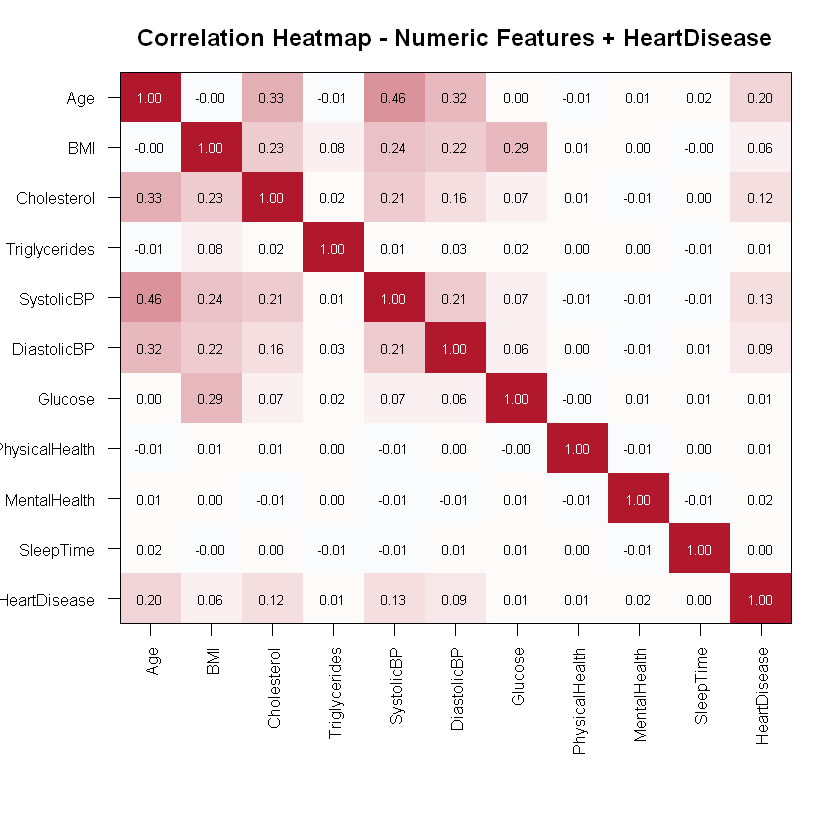

In [40]:
cdf <- df[numeric_features]
cdf[[TARGET_COL]] <- y_enc
M <- cor(cdf)
n_vars <- ncol(M)
nms <- colnames(M)
z <- t(M)[, n_vars:1]   # orient so M[1,1] sits top-left

plot_cols <- colorRampPalette(c("#2166AC", "white", "#B2182B"))(50)
brks <- seq(-1, 1, length.out = 51)

op <- par(mar = c(9, 5, 3, 2))
image(x = seq_len(n_vars), y = seq_len(n_vars), z = z, col = plot_cols, breaks = brks,
      xaxt = "n", yaxt = "n", xlab = "", ylab = "",
      main = paste("Correlation Heatmap - Numeric Features +", TARGET_COL))
axis(1, at = seq_len(n_vars), labels = nms, las = 2, cex.axis = 0.8)
axis(2, at = seq_len(n_vars), labels = rev(nms), las = 2, cex.axis = 0.8)
box()
for (i in seq_len(n_vars)) {
  for (j in seq_len(n_vars)) {
    val <- z[i, j]
    text(i, j, sprintf("%.2f", val), cex = 0.65,
         col = if (abs(val) > 0.6) "white" else "black")
  }
}
par(op)

## 7. Histograms
Distribution of every numeric feature (30 bins each). Look for skew, multi-modality, and
boundary pile-ups — all of which matter when choosing models and transformations later.

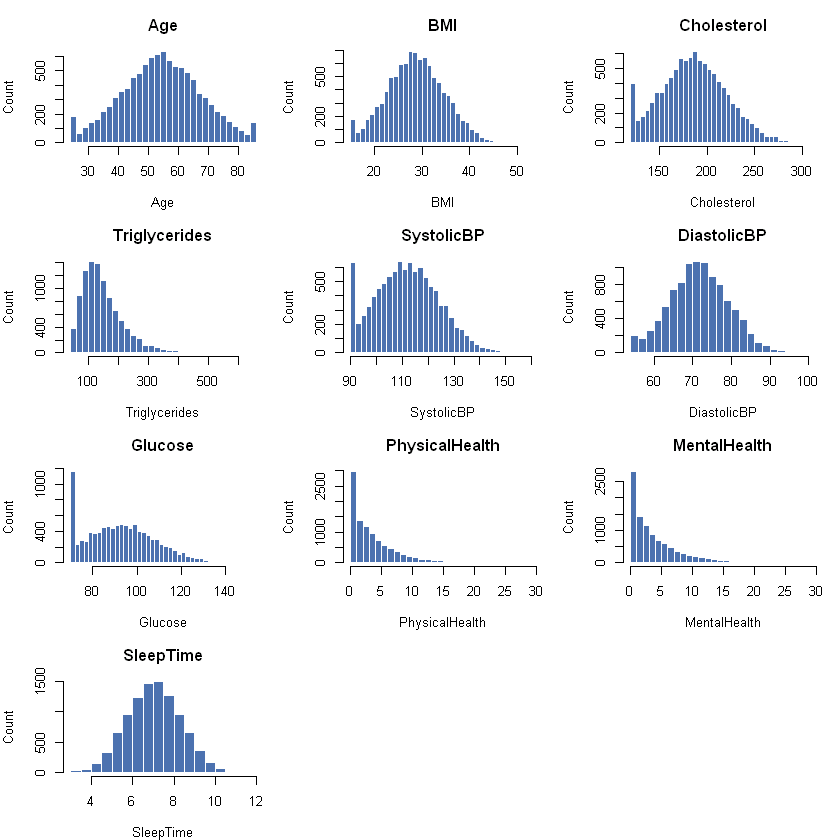

In [41]:
nr <- ceiling(length(numeric_features) / 3)
op <- par(mfrow = c(nr, 3), mar = c(4, 4, 3, 1))
for (col in numeric_features) {
  hist(df[[col]], breaks = 30, col = "#4C72B0", border = "white",
       main = col, xlab = col, ylab = "Count")
}
par(op)

## 8. Boxplots by Heart Disease Status
Each numeric feature split by the target class, making it easy to spot which measurements
separate the two groups (shifted medians = stronger separation).

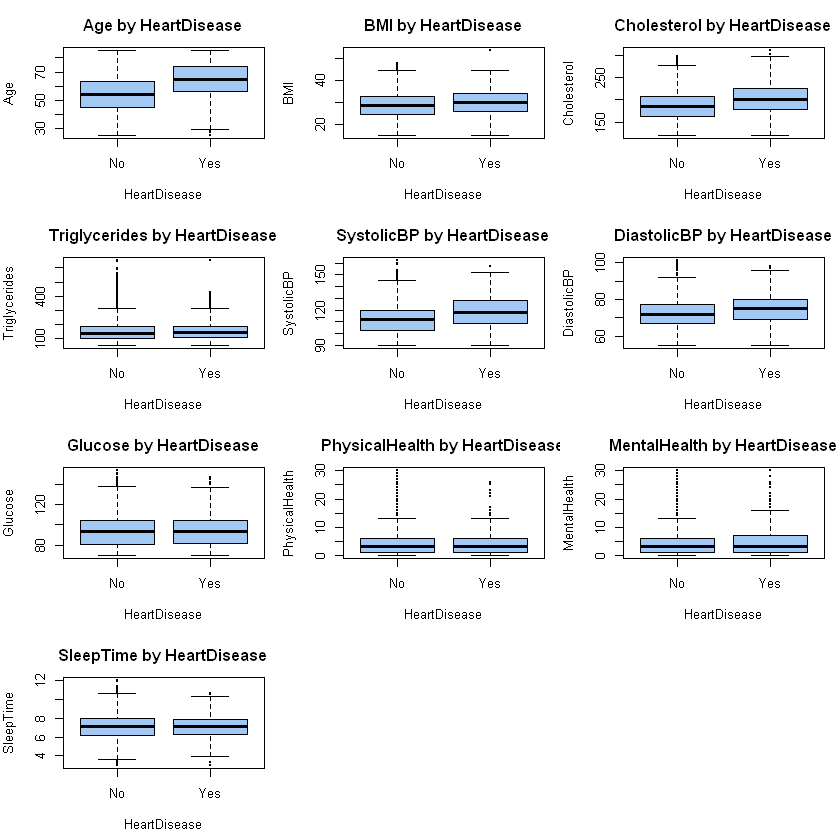

In [42]:
nr <- ceiling(length(numeric_features) / 3)
op <- par(mfrow = c(nr, 3), mar = c(4.5, 4, 3, 1))
for (col in numeric_features) {
  groups <- split(df[[col]], as.character(df[[TARGET_COL]]))
  groups <- groups[plot_labels]
  boxplot(groups, names = names(groups), col = "#A1C9F4", outpch = 19, outcex = 0.4,
          main = paste(col, "by", TARGET_COL), xlab = TARGET_COL, ylab = col)
}
par(op)

## 9. Scatter Plots
Age vs BMI and Cholesterol vs BMI, colored by heart-disease status, to inspect how the risk
groups overlap in two clinically important feature planes.

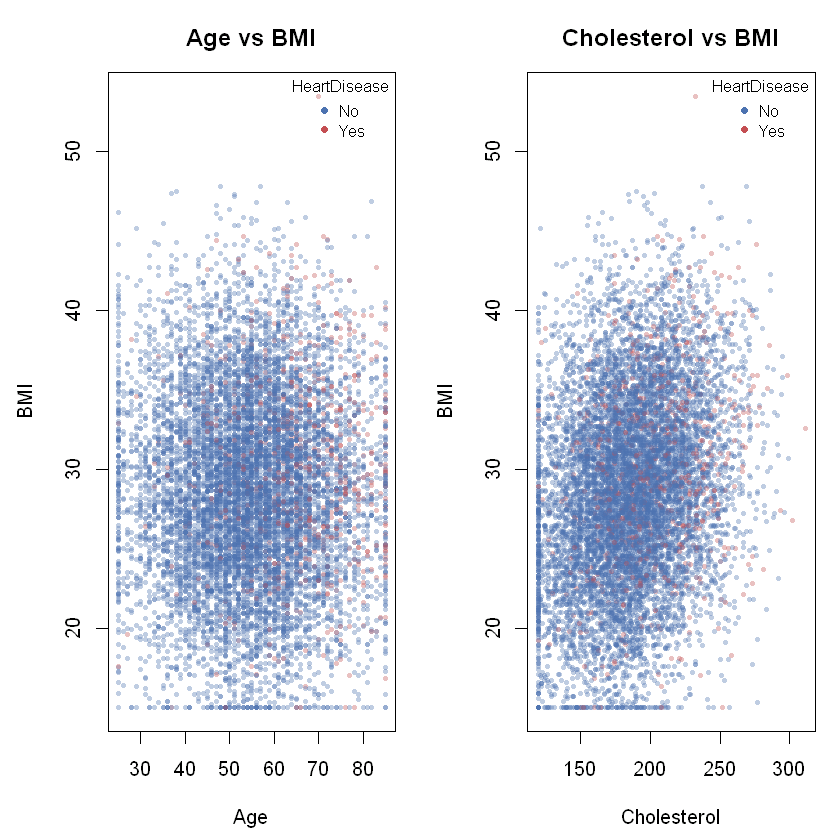

In [43]:
age_col <- find_col(df, "Age")
if (is.null(age_col)) age_col <- numeric_features[1]
bmi_col <- find_col(df, "BMI")
if (is.null(bmi_col)) bmi_col <- numeric_features[min(2, length(numeric_features))]
chol_col <- find_col(df, "Cholesterol")
if (is.null(chol_col)) chol_col <- numeric_features[min(3, length(numeric_features))]

pairs_list <- list(c(age_col, bmi_col, "Age vs BMI"), c(chol_col, bmi_col, "Cholesterol vs BMI"))
lbl_colors <- setNames(c("#4C72B0", "#C44E52", "#55A868", "#8172B3")[seq_along(plot_labels)],
                       plot_labels)
pt_cols <- unname(lbl_colors[as.character(df[[TARGET_COL]])])

op <- par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3, 1))
for (pr in pairs_list) {
  xcol <- pr[1]; ycol <- pr[2]; ttl <- pr[3]
  plot(df[[xcol]], df[[ycol]], col = adjustcolor(pt_cols, alpha.f = 0.35), pch = 16, cex = 0.6,
       xlab = xcol, ylab = ycol, main = ttl)
  legend("topright", legend = plot_labels, col = lbl_colors[plot_labels], pch = 16,
         title = TARGET_COL, cex = 0.8, bty = "n")
}
par(op)

## 10. Outlier Detection (IQR 1.5×IQR Rule)
For every numeric feature, flag values outside `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` and report the
count and percentage of flagged rows per feature, plus how many rows contain at least one outlier.

In [44]:
outlier_rows <- NULL
for (col in numeric_features) {
  qs <- quantile(df[[col]], c(0.25, 0.75), names = FALSE)
  iqr_val <- qs[2] - qs[1]
  low <- qs[1] - 1.5 * iqr_val
  high <- qs[2] + 1.5 * iqr_val
  mask <- df[[col]] < low | df[[col]] > high
  outlier_rows <- rbind(outlier_rows, data.frame(
    Feature = col,
    Q1 = round(qs[1], 2), Q3 = round(qs[2], 2),
    Lower_Bound = round(low, 2), Upper_Bound = round(high, 2),
    Outliers = sum(mask), Outlier_pct = round(100 * mean(mask), 2),
    stringsAsFactors = FALSE
  ))
}
print(outlier_rows, row.names = FALSE)

flag_mat <- sapply(seq_len(nrow(outlier_rows)), function(i) {
  col <- outlier_rows$Feature[i]
  df[[col]] < outlier_rows$Lower_Bound[i] | df[[col]] > outlier_rows$Upper_Bound[i]
})
rows_flagged <- sum(apply(flag_mat, 1, any))
cat(sprintf("\nRows flagged with at least one outlier feature: %s (%.1f%% of the dataset)\n",
            format(rows_flagged, big.mark = ","), 100 * rows_flagged / nrow(df)))

        Feature    Q1    Q3 Lower_Bound Upper_Bound Outliers Outlier_pct
            Age  46.0  64.0        19.0        91.0        0        0.00
            BMI  24.6  32.8        12.3        45.1       27        0.27
    Cholesterol 163.0 210.0        92.5       280.5       37        0.37
  Triglycerides  99.0 183.0       -27.0       309.0      348        3.49
     SystolicBP 103.0 121.0        76.0       148.0       21        0.21
    DiastolicBP  67.0  77.0        52.0        92.0       38        0.38
        Glucose  81.0 104.0        46.5       138.5       38        0.38
 PhysicalHealth   1.0   6.0        -6.5        13.5      419        4.21
   MentalHealth   1.0   6.0        -6.5        13.5      545        5.47
      SleepTime   6.2   8.0         3.5        10.7       61        0.61

Rows flagged with at least one outlier feature: 1,442 (14.5% of the dataset)


## 11. Frequency Tables
Value counts (absolute and percentage) for every categorical feature, target included.

In [45]:
if (length(categorical_cols) > 0) {
  for (col in categorical_cols) {
    tbl <- table(df[[col]])
    tab <- data.frame(
      Count = as.integer(tbl),
      Percent_pct = round(100 * prop.table(tbl), 2),
      row.names = names(tbl)
    )
    cat("---", col, "---\n")
    print(tab)
    cat("\n")
  }
} else {
  cat("No categorical columns detected in this dataset.\n")
}

--- Sex ---
       Count Percent_pct.Var1 Percent_pct.Freq
Female  5128           Female            51.49
Male    4832             Male            48.51

--- Smoking ---
    Count Percent_pct.Var1 Percent_pct.Freq
No   8565               No            85.99
Yes  1395              Yes            14.01

--- AlcoholDrinking ---
    Count Percent_pct.Var1 Percent_pct.Freq
No   8532               No            85.66
Yes  1428              Yes            14.34

--- Stroke ---
    Count Percent_pct.Var1 Percent_pct.Freq
No   9716               No            97.55
Yes   244              Yes             2.45

--- DiffWalking ---
    Count Percent_pct.Var1 Percent_pct.Freq
No   8619               No            86.54
Yes  1341              Yes            13.46

--- Diabetes ---
    Count Percent_pct.Var1 Percent_pct.Freq
No   9292               No            93.29
Yes   668              Yes             6.71

--- PhysicalActivity ---
    Count Percent_pct.Var1 Percent_pct.Freq
No   2448           

## 12. Unique Values
Per-column unique-count summary (sorted table + horizontal bar chart). Low-cardinality numeric
columns often turn out to be encoded categorical features; high-cardinality columns are continuous.

           Column Unique_Count Data_Type Unique_pct
    Triglycerides          396   numeric       3.98
              BMI          318   numeric       3.19
      Cholesterol          181   numeric       1.82
        SleepTime           88   numeric       0.88
          Glucose           80   numeric       0.80
       SystolicBP           69   numeric       0.69
              Age           62   numeric       0.62
      DiastolicBP           47   numeric       0.47
   PhysicalHealth           31   numeric       0.31
     MentalHealth           31   numeric       0.31
              Sex            2    factor       0.02
          Smoking            2    factor       0.02
  AlcoholDrinking            2    factor       0.02
           Stroke            2    factor       0.02
      DiffWalking            2    factor       0.02
         Diabetes            2    factor       0.02
 PhysicalActivity            2    factor       0.02
           Asthma            2    factor       0.02
    KidneyDi

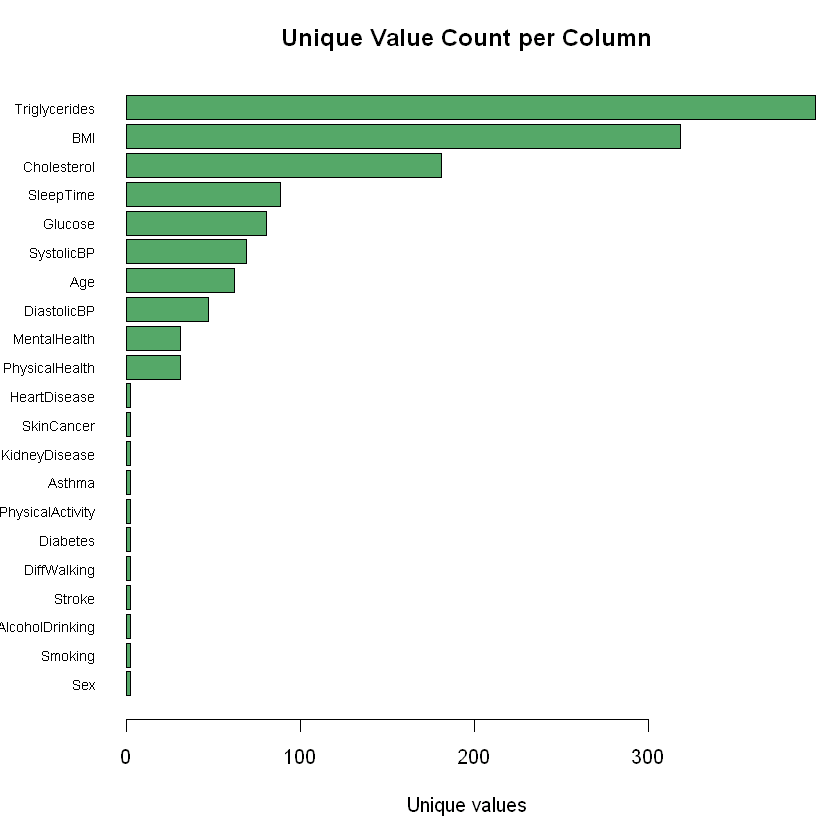

In [46]:
uniq_counts <- sapply(df, function(x) length(unique(x[!is.na(x)])))
unique_summary <- data.frame(
  Column = names(df),
  Unique_Count = as.integer(uniq_counts),
  Data_Type = sapply(df, function(x) paste(class(x), collapse = ", ")),
  Unique_pct = round(100 * as.numeric(uniq_counts) / nrow(df), 2),
  stringsAsFactors = FALSE
)
unique_summary <- unique_summary[order(-unique_summary$Unique_Count), ]
rownames(unique_summary) <- NULL
print(unique_summary, row.names = FALSE)

vals <- setNames(unique_summary$Unique_Count, unique_summary$Column)
op <- par(mar = c(5, 5, 3, 1))
barplot(sort(vals), horiz = TRUE, col = "#55A868",
        xlab = "Unique values", main = "Unique Value Count per Column",
        las = 1, cex.names = 0.7)
par(op)

## 13. Simple Linear Regression (2 cells, 1 plot)
A single-feature linear regression: the encoded heart-disease target regressed on **BMI**
(the first numeric feature if BMI is absent). Cell 1 fits the model with `lm()` and reports the
fitted equation and error metrics; cell 2 draws the one plot — actual points with the fitted line.

In [47]:
simple_feature <- find_col(df, "BMI")
if (is.null(simple_feature)) simple_feature <- numeric_features[1]

model_df <- data.frame(target = as.numeric(y_enc), df[[simple_feature]],
                       stringsAsFactors = FALSE)
names(model_df)[2] <- simple_feature

# stratified 80/20 train-test split (80% of each target class for training)
set.seed(RANDOM_STATE)
strat <- split(seq_len(nrow(model_df)), y_enc)
train_idx <- sort(unlist(lapply(strat, function(ix) sample(ix, floor(0.8 * length(ix))))))
test_idx <- setdiff(seq_len(nrow(model_df)), train_idx)

fml <- as.formula(paste("target ~", paste0("`", simple_feature, "`")))
lin_reg <- lm(fml, data = model_df)
pred_te <- predict(lin_reg, newdata = model_df[test_idx, ])

y_te <- y_enc[test_idx]
r2_test <- 1 - sum((y_te - pred_te)^2) / sum((y_te - mean(y_te))^2)
rmse_te <- sqrt(mean((y_te - pred_te)^2))
mae_te <- mean(abs(y_te - pred_te))

coefs <- coef(lin_reg)
cat("Feature         :", simple_feature, "\n")
cat(sprintf("Fitted equation : %s = %.4f + (%.4f) x %s\n",
            TARGET_COL, coefs[1], coefs[2], simple_feature))
cat(sprintf("Train R2        : %.4f\n", summary(lin_reg)$r.squared))
cat(sprintf("Test  R2        : %.4f\n", r2_test))
cat(sprintf("Test  RMSE      : %.4f\n", rmse_te))
cat(sprintf("Test  MAE       : %.4f\n", mae_te))

Feature         : BMI 
Fitted equation : HeartDisease = -0.0029 + (0.0026) x BMI
Train R2        : 0.0035
Test  R2        : 0.0073
Test  RMSE      : 0.2563
Test  MAE       : 0.1317


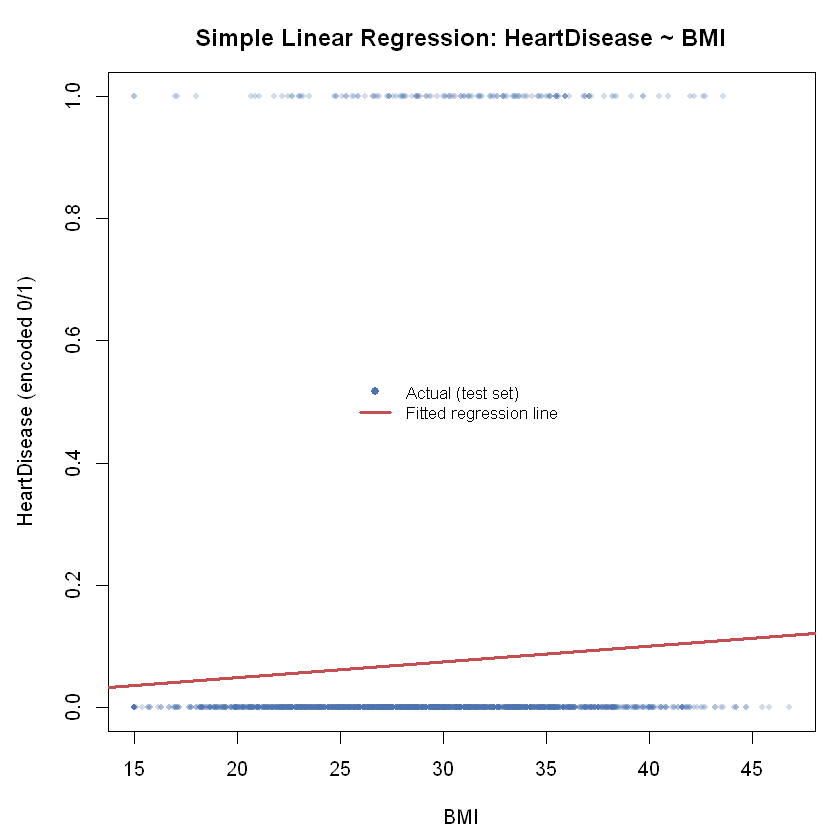

In [48]:
op <- par(mar = c(4.5, 4.5, 3, 1))
plot(model_df[test_idx, simple_feature], y_te,
     col = adjustcolor("#4C72B0", alpha.f = 0.25), pch = 16, cex = 0.7,
     xlab = simple_feature, ylab = paste0(TARGET_COL, " (encoded 0/1)"),
     main = paste("Simple Linear Regression:", TARGET_COL, "~", simple_feature))
abline(lin_reg, col = "#C44E52", lwd = 2.5)
legend("center", legend = c("Actual (test set)", "Fitted regression line"),
       col = c("#4C72B0", "#C44E52"), pch = c(16, NA), lty = c(NA, 1),
       lwd = c(NA, 2.5), cex = 0.85, bty = "n")
par(op)

## 14. Multiple Linear Regression (2 cells, 1 plot)
Multiple linear regression with **all numeric features** predicting the encoded target.
Cell 1 fits the model with `lm()` and reports the coefficient table plus error metrics;
cell 2 draws the one plot — actual vs predicted values against the perfect-prediction line.

In [49]:
model_df_m <- data.frame(target = as.numeric(y_enc), df[numeric_features],
                         stringsAsFactors = FALSE)
names(model_df_m) <- c("target", numeric_features)

# stratified 80/20 train-test split
set.seed(RANDOM_STATE)
strat_m <- split(seq_len(nrow(model_df_m)), y_enc)
train_idx_m <- sort(unlist(lapply(strat_m, function(ix) sample(ix, floor(0.8 * length(ix))))))
test_idx_m <- setdiff(seq_len(nrow(model_df_m)), train_idx_m)

fml_m <- as.formula(paste("target ~",
                          paste(paste0("`", numeric_features, "`"), collapse = " + ")))
lin_multi <- lm(fml_m, data = model_df_m)
pred_te_m <- predict(lin_multi, newdata = model_df_m[test_idx_m, ])

y_te_m <- y_enc[test_idx_m]
r2_test_m <- 1 - sum((y_te_m - pred_te_m)^2) / sum((y_te_m - mean(y_te_m))^2)
rmse_te_m <- sqrt(mean((y_te_m - pred_te_m)^2))
mae_te_m <- mean(abs(y_te_m - pred_te_m))

coefs_m <- coef(lin_multi)
coef_table <- data.frame(Feature = names(coefs_m)[-1],
                         Coefficient = round(coefs_m[-1], 4), stringsAsFactors = FALSE)
coef_table <- coef_table[order(-abs(coef_table$Coefficient)), ]
rownames(coef_table) <- NULL

cat("Features used   :", length(numeric_features), "numeric features\n")
cat(sprintf("Intercept       : %.4f\n", coefs_m[1]))
cat(sprintf("Train R2        : %.4f\n", summary(lin_multi)$r.squared))
cat(sprintf("Test  R2        : %.4f\n", r2_test_m))
cat(sprintf("Test  RMSE      : %.4f\n", rmse_te_m))
cat(sprintf("Test  MAE       : %.4f\n", mae_te_m))
print(coef_table, row.names = FALSE)

Features used   : 10 numeric features
Intercept       : -0.3284
Train R2        : 0.0467
Test  R2        : 0.0447
Test  RMSE      : 0.2514
Test  MAE       : 0.1319
        Feature Coefficient
            Age      0.0032
            BMI      0.0017
   MentalHealth      0.0009
     SystolicBP      0.0007
 PhysicalHealth      0.0005
    Cholesterol      0.0004
    DiastolicBP      0.0004
        Glucose     -0.0001
      SleepTime     -0.0001
  Triglycerides      0.0000


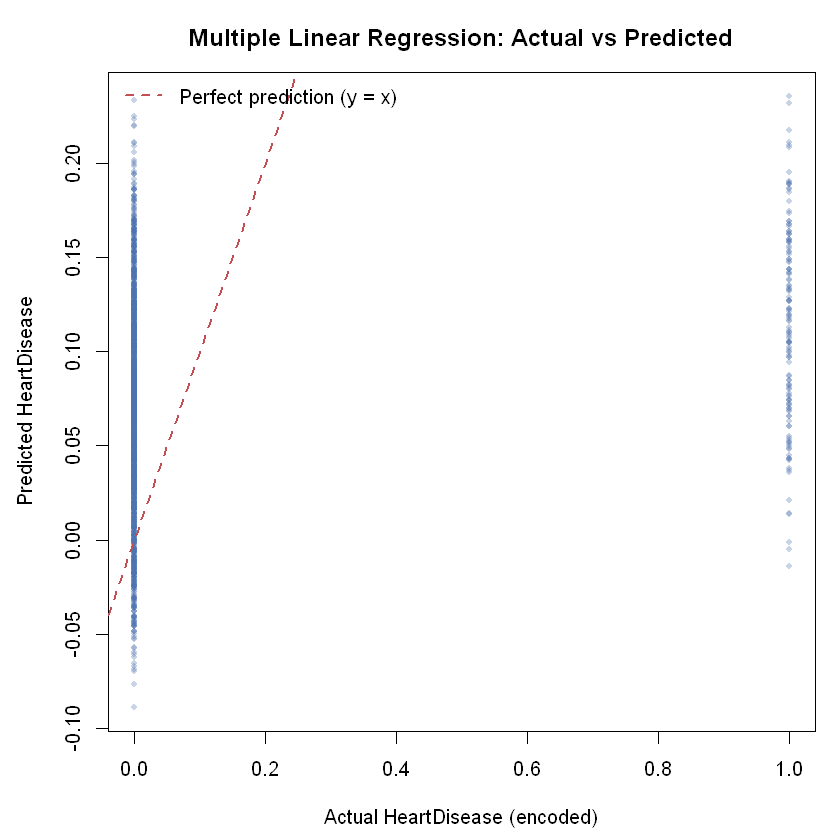

In [50]:
op <- par(mar = c(4.5, 4.5, 3, 1))
plot(y_te_m, pred_te_m, col = adjustcolor("#4C72B0", alpha.f = 0.3), pch = 16, cex = 0.7,
     xlab = paste("Actual", TARGET_COL, "(encoded)"), ylab = paste("Predicted", TARGET_COL),
     main = "Multiple Linear Regression: Actual vs Predicted")
abline(0, 1, col = "#C44E52", lwd = 2, lty = 2)
legend("topleft", legend = "Perfect prediction (y = x)",
       col = "#C44E52", lty = 2, lwd = 2, bty = "n")
par(op)